# 04b Classification race

In 04a we predicted consumption and then ranked the households. Here we predict poverty directly: the target is `poor` (1 = consumption below the local poverty line), and each model gives every household a probability of being poor. In each village, the households with the highest probability get the transfer.

Models: logistic regression (no penalty, L2, L1), boosting classifier, neural network.
- Tuning score: log loss (lower = better probabilities), on the saved village folds.
- Race metric: recall at the quota, as in 04a.

### 1. Setup and loading

In [12]:
import sys
sys.path.append("..")

import warnings
warnings.filterwarnings("ignore", message=".*penalty.*")   # newer scikit-learn versions warn that 'penalty' will be renamed; results are the same

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression                         # logistic models
from sklearn.ensemble import HistGradientBoostingClassifier                 # boosting
from sklearn.neural_network import MLPClassifier                            # neural network
from sklearn.model_selection import cross_val_score, PredefinedSplit, RandomizedSearchCV, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score

from src.utils import SEED, load_data, select_by_quota, recall_at_quota, within_village_auc
from src.features import SET_A, without_village_level, make_preprocessor

train, test = load_data()                 # test is not used in this notebook
cv = PredefinedSplit(train["fold"])       # the 5 saved village folds, same as in 04a
print("SEED:", SEED, "| train:", train.shape, "| villages:", train["hhea"].nunique())

SEED: 40 | train: (4090, 113) | villages: 512


### 2. Features (X) and target (y)

In [13]:
# Logistic models: set A without the village-level columns (as the linear models in 04a)
features = without_village_level(SET_A)            # 53 columns
X_train = train[features].astype(float)            

# Boosting and neural net: all of set A (with district, urban, village facilities)
features_full = SET_A                              # 66 columns
X_train_full = train[features_full].copy()
num_cols = [c for c in features_full if c != "kabu"]          # all columns except the district code
X_train_full[num_cols] = X_train_full[num_cols].astype(float)

y_train = train["poor"].astype(int)                # target: 1 = poor, 0 = not poor

share_poor = y_train.mean()
baseline_logloss = -(share_poor * np.log(share_poor) + (1 - share_poor) * np.log(1 - share_poor))
print("features:", len(features), "| with village-level columns:", len(features_full))
print(f"share poor: {share_poor:.3f}")
print(f"log loss if we give everyone the same probability ({share_poor:.2f}): {baseline_logloss:.4f}")

features: 53 | with village-level columns: 66
share poor: 0.363
log loss if we give everyone the same probability (0.36): 0.6549


The target is fairly balanced (36% poor), so we need no special treatment for class imbalance.

**Log loss** measures how good the predicted probabilities are. It punishes a model that is confident and wrong. If we give every household the same probability (36%), the log loss is 0.655. This is the reference, like "always guess the mean" for the MSE in 04a.

Filling missing values and scaling happen inside the pipeline (`make_preprocessor`), so they are learned on the training folds only.

### 3. Logistic regression without penalty

In [14]:
logit = Pipeline([
    ("prep", make_preprocessor(features, drop_first=True)),      # fill + Yeo-Johnson + scale
    ("model", LogisticRegression(penalty=None, max_iter=5000)),  # no penalty
])
cv_score = cross_val_score(logit, X_train, y_train, cv=cv, scoring="neg_log_loss")
logit_cv_ll = -np.mean(cv_score)      # flip the sign, average over the 5 folds

print("log loss per fold:", (-cv_score).round(4))
print(f"Logit CV log loss: {logit_cv_ll:.4f} | same probability for everyone: {baseline_logloss:.4f}")

# Fit on all training households and look at the coefficients
logit.fit(X_train, y_train)
names = logit.named_steps["prep"].get_feature_names_out()
logit_coefs = pd.Series(logit.named_steps["model"].coef_[0], index=names)
top = logit_coefs.abs().sort_values(ascending=False).index[:10]     # 10 largest coefficients (by size)
display(logit_coefs.loc[top].round(3))

log loss per fold: [0.4783 0.4548 0.5372 0.5191 0.4883]
Logit CV log loss: 0.4955 | same probability for everyone: 0.6549


hhsize     1.694
hhsize2   -0.891
troof      0.347
hhage2     0.330
se2_117   -0.327
se2_125   -0.314
hhage     -0.278
fcook     -0.263
se2_17    -0.244
pcfloor   -0.225
dtype: float64

**Result:**

The logistic regression has a CV log loss of 0.496, clearly below the reference of 0.655. So the features tell us a lot about who is poor.

The coefficients have the opposite sign to OLS in 04a, because here a positive coefficient means "more likely poor". The largest is `hhsize` (+1.69): bigger households are more often poor. `hhsize2` is negative (-0.89), so the effect gets weaker for very big households.

Assets (computer, motorcycle, refrigerator) and more floor area per person make poverty less likely. It is the same picture as in 04a. We do not read too much into single coefficients: many features overlap, so a coefficient shows the effect with all the others held fixed.

### 4. Logistic regression with L2 and L1 penalty

As Ridge and Lasso in 04a, but for classification. In scikit-learn the strength is set with C, which works the other way round than alpha: a **small C is a strong penalty**, a very large C is no penalty.
- L2 makes all coefficients smaller (like Ridge).
- L1 can set coefficients exactly to 0 (like Lasso). It needs the solver `saga`.

In [15]:
Cs = np.logspace(-3, 3, 13)     # 13 values from 0.001 (strong penalty) to 1000 (almost none)

l2_scores, l1_scores = [], []
for C in Cs:
    l2_model = Pipeline([("prep", make_preprocessor(features)),
                         ("model", LogisticRegression(penalty="l2", C=C, max_iter=5000))])
    l2_scores.append(-cross_val_score(l2_model, X_train, y_train, cv=cv, scoring="neg_log_loss").mean())

    l1_model = Pipeline([("prep", make_preprocessor(features)),
                         ("model", LogisticRegression(penalty="l1", solver="saga", C=C,
                                                      max_iter=5000, random_state=SEED))])
    l1_scores.append(-cross_val_score(l1_model, X_train, y_train, cv=cv, scoring="neg_log_loss").mean())

best_C_l2, best_score_l2 = Cs[np.argmin(l2_scores)], np.min(l2_scores)
best_C_l1, best_score_l1 = Cs[np.argmin(l1_scores)], np.min(l1_scores)
print(f"L2: best C {best_C_l2:.3f} | CV log loss {best_score_l2:.4f}")
print(f"L1: best C {best_C_l1:.3f} | CV log loss {best_score_l1:.4f}")
print(f"no penalty:          CV log loss {logit_cv_ll:.4f}")

L2: best C 0.100 | CV log loss 0.4924
L1: best C 0.316 | CV log loss 0.4906
no penalty:          CV log loss 0.4955


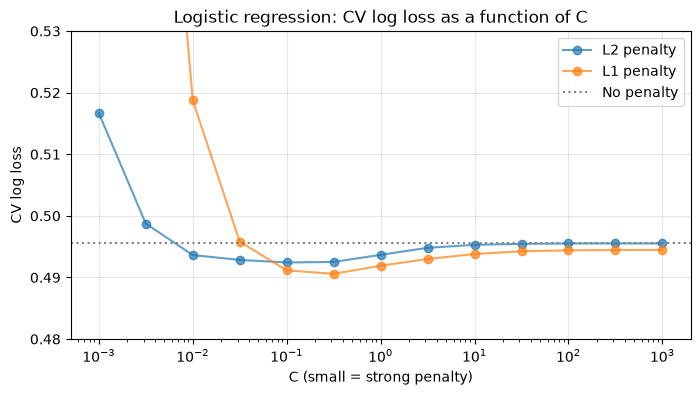

L1 sets 4 of 53 coefficients to 0: ['hhage', 'hhmalemarr', 'hheduc3', 'hhsector1']


In [16]:
# Plot: CV log loss for each C
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(Cs, l2_scores, marker="o", alpha=0.7, label="L2 penalty")
ax.plot(Cs, l1_scores, marker="o", alpha=0.7, label="L1 penalty")
ax.axhline(logit_cv_ll, color="grey", linestyle=":", label="No penalty")

ax.set_xscale("log")
ax.set_ylim(0.48, 0.53)       # zoom in; very strong penalties are far above this range
ax.set_xlabel("C (small = strong penalty)")
ax.set_ylabel("CV log loss")
ax.set_title("Logistic regression: CV log loss as a function of C")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

# Which features does L1 drop?
logit_l1 = Pipeline([("prep", make_preprocessor(features)),
                     ("model", LogisticRegression(penalty="l1", solver="saga", C=best_C_l1,
                                                  max_iter=5000, random_state=SEED))])
logit_l1.fit(X_train, y_train)
l1_coefs = pd.Series(logit_l1.named_steps["model"].coef_[0],
                     index=logit_l1.named_steps["prep"].get_feature_names_out())
zero = l1_coefs[l1_coefs == 0].index.tolist()
print(f"L1 sets {len(zero)} of {len(features)} coefficients to 0:", zero)

**Result:**

The penalty helps only a little: the log loss goes from 0.496 (no penalty) to 0.492 (L2) and 0.491 (L1). The differences between the folds are much larger (0.45 to 0.54), so the three logistic models are tied.

L1 sets only 4 of 53 coefficients to 0 (`hhage`, `hhmalemarr`, `hheduc3`, `hhsector1`). The reason is the same as in 04a: we have many households per feature, and the features were already chosen by the government.

### 5. Boosting classifier

Same idea and same search as in 04a: many small trees, each one correcting the errors of the trees before. Boosting uses all of set A (with the village-level columns) and needs no scaling. `RandomizedSearchCV` tries 40 random combinations from the same grid as in 04a and keeps the one with the lowest CV log loss. The built-in early stopping is off, because it would hold out random households and ignore the villages.

In [17]:
boost = Pipeline([
    ("prep", make_preprocessor(features_full, scale=False)),     # fill + district one-hot, no scaling
    ("model", HistGradientBoostingClassifier(early_stopping=False, random_state=SEED)),
])
param_boost = {
    "model__learning_rate": [0.02, 0.05, 0.1],
    "model__max_iter": [100, 200, 400, 800],
    "model__max_depth": [2, 3, 4, 5],
    "model__min_samples_leaf": [20, 50, 100],
    "model__l2_regularization": [0, 0.1, 1],
}
search_boost = RandomizedSearchCV(boost, param_distributions=param_boost, n_iter=40,
                                  scoring="neg_log_loss", cv=cv, random_state=SEED,
                                  return_train_score=True, n_jobs=-1)
search_boost.fit(X_train_full, y_train)       # takes 1-2 minutes

best_params_boost = search_boost.best_params_
best_score_boost = -search_boost.best_score_
print("Best settings:", best_params_boost)
print(f"Boosting CV log loss: {best_score_boost:.4f} | Logit: {logit_cv_ll:.4f}")

results_boost = pd.DataFrame(search_boost.cv_results_)
results_boost["CV log loss"] = -results_boost["mean_test_score"]
results_boost["train log loss"] = -results_boost["mean_train_score"]
display(results_boost.sort_values("CV log loss")[["params", "CV log loss", "std_test_score", "train log loss"]].head(5).round(4))

# Check: the same boosting, but without the village-level columns
boost_nv = Pipeline([
    ("prep", make_preprocessor(features, scale=False)),
    ("model", HistGradientBoostingClassifier(early_stopping=False, random_state=SEED)),
])
boost_nv.set_params(**best_params_boost)      # same settings as the best boosting above
best_score_boost_nv = -cross_val_score(boost_nv, X_train, y_train, cv=cv, scoring="neg_log_loss").mean()
print(f"Boosting without village columns: CV log loss {best_score_boost_nv:.4f}")

Best settings: {'model__min_samples_leaf': 100, 'model__max_iter': 800, 'model__max_depth': 2, 'model__learning_rate': 0.05, 'model__l2_regularization': 0.1}
Boosting CV log loss: 0.4705 | Logit: 0.4955


,params,CV log loss,std_test_score,train log loss
19,"{'model__min_samples_leaf': 100, 'model__max_i...",0.4705,0.0186,0.3979
37,"{'model__min_samples_leaf': 100, 'model__max_i...",0.4714,0.0152,0.4269
7,"{'model__min_samples_leaf': 50, 'model__max_it...",0.4716,0.0182,0.3837
8,"{'model__min_samples_leaf': 50, 'model__max_it...",0.4721,0.0178,0.4226
33,"{'model__min_samples_leaf': 20, 'model__max_it...",0.4727,0.0186,0.3830


Boosting without village columns: CV log loss 0.4893


**Result:**

The best boosting model again uses very small trees (depth 2), here 800 of them with a learning rate of 0.05. Its CV log loss is 0.471, lower than the logistic regression (0.496). The training log loss is 0.398, so it overfits a little, but not badly.

Without the village-level columns the log loss is 0.489, close to the logistic models. So, as in 04a, most of the gain comes from the village-level columns: they help to say which *villages* are poorer. Section 7 shows whether this helps to choose households *inside* a village.

Note: the "without village columns" check reuses the settings tuned with these columns, so it may be slightly too pessimistic.

### 6. Neural network

A small neural network (MLP) with one or two hidden layers. It uses all of set A, with scaling (neural networks need scaled inputs, like Ridge and Lasso). We tune the size of the hidden layers, the penalty `alpha` and the learning rate with a grid search (50 combinations).

We use early stopping: training stops when the loss on a held-out 10% of the training data no longer improves. These 10% are random households from the *training folds*, so the validation villages are never seen. But neighbours can be on both sides of this inner split, so the stopping point may come a bit late.

In [18]:
nn = Pipeline([
    ("prep", make_preprocessor(features_full)),      # fill + Yeo-Johnson + scale
    ("model", MLPClassifier(early_stopping=True, validation_fraction=0.1, n_iter_no_change=10,
                            max_iter=500, random_state=SEED)),
])
param_nn = {
    "model__hidden_layer_sizes": [(8,), (16,), (32,), (64,), (32, 16)],   # neurons per hidden layer
    "model__alpha": [0.01, 0.1, 1, 3, 10],                                # L2 penalty on the weights
    "model__learning_rate_init": [0.001, 0.01],                           # step size
}
search_nn = GridSearchCV(nn, param_grid=param_nn, scoring="neg_log_loss", cv=cv,
                         return_train_score=True, n_jobs=-1)              # all 50 combinations
search_nn.fit(X_train_full, y_train)

best_params_nn = search_nn.best_params_
best_score_nn = -search_nn.best_score_
print("Best settings:", best_params_nn)
print(f"Neural net CV log loss: {best_score_nn:.4f} | Logit: {logit_cv_ll:.4f} | Boosting: {best_score_boost:.4f}")
print("training rounds (epochs) until early stopping:", search_nn.best_estimator_.named_steps["model"].n_iter_)

results_nn = pd.DataFrame(search_nn.cv_results_)
results_nn["CV log loss"] = -results_nn["mean_test_score"]
results_nn["train log loss"] = -results_nn["mean_train_score"]
display(results_nn.sort_values("CV log loss")[["params", "CV log loss", "std_test_score", "train log loss"]].head(5).round(4))

Best settings: {'model__alpha': 3, 'model__hidden_layer_sizes': (16,), 'model__learning_rate_init': 0.01}
Neural net CV log loss: 0.4705 | Logit: 0.4955 | Boosting: 0.4705
training rounds (epochs) until early stopping: 18


,params,CV log loss,std_test_score,train log loss
33,"{'model__alpha': 3, 'model__hidden_layer_sizes...",0.4705,0.0236,0.4195
36,"{'model__alpha': 3, 'model__hidden_layer_sizes...",0.4725,0.0205,0.4153
34,"{'model__alpha': 3, 'model__hidden_layer_sizes...",0.4743,0.0213,0.4299
37,"{'model__alpha': 3, 'model__hidden_layer_sizes...",0.4746,0.0187,0.4234
35,"{'model__alpha': 3, 'model__hidden_layer_sizes...",0.4753,0.0208,0.4275


**Result:**

The best network is small: one hidden layer with 16 neurons and a strong penalty (alpha = 3, in the middle of the grid). Its CV log loss is 0.471, the same as boosting.

The search prefers small networks with a strong penalty: with about 4,000 households, there is not enough data for a flexible model to find patterns that a simple model misses.

The neural net is also less stable than the other models. With the same settings but a different random seed, its log loss moves between 0.47 and 0.49 and its recall between 55% and 56%. Our seed is at the good end, so we read the neural net's result with caution.

### 7. CV recall at the quota (the race metric)

Same procedure as in 04a: fit on 4 folds, predict the 5th, select the households village by village, compare with `poor`. The only difference: the score is now the predicted **probability of being poor**, so the households with the *highest* score get the transfer.

We also add a logistic regression **with** the village-level columns, to check whether leaving them out changes anything.

In [19]:
metrics = ["recall", "precision", "accuracy", "roc_auc", "within_auc"]
references = ["Government formula", "Random", "Perfect ranking"]

def targeting_metrics(val, score, name, k, higher_is_poorer):
    selected = select_by_quota(val, score, higher_is_poorer=higher_is_poorer)
    poor = val["poor"].astype(int)
    s = val[score] if higher_is_poorer else -val[score]     # so that a high value always means "poorer"
    return {
        "model": name, "fold": k,
        "recall": recall_at_quota(val, selected),           # poor selected / all poor (main metric)
        "precision": poor[selected == 1].mean(),            # share of poor among the selected
        "accuracy": (selected == poor).mean(),              # correct decisions / all households
        "roc_auc": roc_auc_score(poor, s),                  # ranking over all households
        "within_auc": within_village_auc(val, score, higher_is_poorer=higher_is_poorer),   # only pairs in the same village
    }

def make_models():
    """All classifiers with their chosen settings (new, unfitted copies), each with its feature table."""
    hgb = HistGradientBoostingClassifier(early_stopping=False, random_state=SEED)
    mlp = MLPClassifier(early_stopping=True, validation_fraction=0.1, n_iter_no_change=10,
                        max_iter=500, random_state=SEED)
    return {
        "Logit": (Pipeline([("prep", make_preprocessor(features, drop_first=True)),
                            ("model", LogisticRegression(penalty=None, max_iter=5000))]), X_train),
        "Logit L2": (Pipeline([("prep", make_preprocessor(features)),
                               ("model", LogisticRegression(penalty="l2", C=best_C_l2, max_iter=5000))]), X_train),
        "Logit L1": (Pipeline([("prep", make_preprocessor(features)),
                               ("model", LogisticRegression(penalty="l1", solver="saga", C=best_C_l1,
                                                            max_iter=5000, random_state=SEED))]), X_train),
        "Logit (with village)": (Pipeline([("prep", make_preprocessor(features_full, drop_first=True)),
                                           ("model", LogisticRegression(penalty=None, max_iter=5000))]), X_train_full),
        "Boosting": (Pipeline([("prep", make_preprocessor(features_full, scale=False)),
                               ("model", hgb)]).set_params(**best_params_boost), X_train_full),
        "Boosting (no village)": (Pipeline([("prep", make_preprocessor(features, scale=False)),
                                            ("model", HistGradientBoostingClassifier(early_stopping=False, random_state=SEED))
                                            ]).set_params(**best_params_boost), X_train),
        "Neural net": (Pipeline([("prep", make_preprocessor(features_full)),
                                 ("model", mlp)]).set_params(**best_params_nn), X_train_full),
    }

rng = np.random.default_rng(SEED)
rows = []
for k, (train_idx, val_idx) in enumerate(cv.split()):
    val = train.iloc[val_idx].copy()                                   # the validation villages
    for name, (model, X) in make_models().items():
        model.fit(X.iloc[train_idx], y_train.iloc[train_idx])          # learn on the other 4 folds
        val[name] = model.predict_proba(X.iloc[val_idx])[:, 1]         # probability of being poor
        rows.append(targeting_metrics(val, name, name, k, higher_is_poorer=True))

    rows.append(targeting_metrics(val, "pcexppred", "Government formula", k, higher_is_poorer=False))
    rows.append(targeting_metrics(val, "LOGCONSUMPTION", "Perfect ranking", k, higher_is_poorer=False))

    random_runs = []                                                   # floor: 100 random rankings
    for r in range(100):
        val["Random"] = rng.random(len(val))
        random_runs.append(targeting_metrics(val, "Random", "Random", k, higher_is_poorer=True))
    random_row = pd.DataFrame(random_runs)[metrics].mean().to_dict()
    random_row.update(model="Random", fold=k)
    rows.append(random_row)

fold_results = pd.DataFrame(rows)
by_fold = fold_results.pivot(index="fold", columns="model", values="recall")
display(by_fold.round(3))

summary = fold_results.groupby("model")[metrics].agg(["mean", "std"])
summary = summary.sort_values(("recall", "mean"), ascending=False)
display(summary.round(3))

model,Boosting,Boosting (no village),Government formula,Logit,Logit (with village),Logit L1,Logit L2,Neural net,Perfect ranking,Random
fold,,,,,,,,,,
0,0.579,0.579,0.559,0.589,0.585,0.592,0.589,0.579,0.716,0.370
1,0.597,0.585,0.544,0.582,0.594,0.582,0.579,0.582,0.682,0.374
2,0.525,0.512,0.548,0.538,0.535,0.535,0.535,0.525,0.664,0.353
3,0.583,0.562,0.552,0.583,0.587,0.580,0.583,0.583,0.729,0.382
4,0.513,0.509,0.498,0.516,0.520,0.509,0.513,0.523,0.639,0.341


recall        precision        accuracy        roc_auc  \
                        mean    std      mean    std     mean    std    mean   
model                                                                          
Perfect ranking        0.686  0.037     0.769  0.033    0.811  0.013   0.993   
Logit (with village)   0.564  0.034     0.632  0.043    0.723  0.016   0.839   
Logit                  0.562  0.032     0.630  0.040    0.721  0.014   0.824   
Logit L2               0.560  0.034     0.627  0.040    0.720  0.015   0.824   
Logit L1               0.560  0.036     0.627  0.044    0.720  0.017   0.825   
Boosting               0.559  0.038     0.627  0.047    0.720  0.019   0.841   
Neural net             0.558  0.031     0.626  0.038    0.719  0.015   0.839   
Boosting (no village)  0.549  0.037     0.616  0.049    0.713  0.021   0.826   
Government formula     0.540  0.024     0.606  0.038    0.706  0.013   0.795   
Random                 0.364  0.017     0.408  0.020    0.578  0.012   0.499   

                             within_auc         
                         std       mean    std  
model                                           
Perfect ranking        0.002      1.000  0.000  
Logit (with village)   0.024      0.822  0.024  
Logit                  0.024      0.814  0.027  
Logit L2               0.026      0.815  0.029  
Logit L1               0.025      0.816  0.028  
Boosting               0.020      0.824  0.026  
Neural net             0.025      0.822  0.022  
Boosting (no village)  0.022      0.811  0.022  
Government formula     0.026      0.777  0.023  
Random                 0.001      0.500  0.002

**Result:**

All classifiers find about 56 out of 100 poor households: logistic regression 56.2%, L2 and L1 56.0%, boosting 55.9%, neural net 55.8%. The government formula finds 54.0%, a random ranking 36.4% and a perfect ranking 68.6%.

Boosting and the neural net had the best log loss, but they do not find more poor households. As in 04a, the village-level columns help to predict which villages are poorer, but inside a village they are the same for everyone. The within-village AUC is 0.82 for boosting and the neural net and 0.81 for the logistic regression, so they rank neighbours only slightly better.

The logistic regression with the village-level columns reaches 56.4%, practically the same as without them (56.2%). So leaving them out of the linear models costs nothing.

### 8. Classification winner

Same rule as in 04a: rank the models by mean CV recall at the quota. If a simpler model is within one standard deviation of the best, the simpler model wins. The logistic regression without penalty is the simplest (nothing to tune), then L2 and L1, then boosting, then the neural net.

In [20]:
# Log loss of the logistic regression with the village-level columns (for a fair comparison with boosting and the neural net)
logit_village = Pipeline([("prep", make_preprocessor(features_full, drop_first=True)),
                          ("model", LogisticRegression(penalty=None, max_iter=5000))])
logit_village_ll = -cross_val_score(logit_village, X_train_full, y_train, cv=cv, scoring="neg_log_loss").mean()

cv_logloss = pd.Series({"Logit": logit_cv_ll, "Logit (with village)": logit_village_ll,
                        "Logit L2": best_score_l2, "Logit L1": best_score_l1,
                        "Boosting": best_score_boost, "Boosting (no village)": best_score_boost_nv,
                        "Neural net": best_score_nn})

final = pd.DataFrame({
    "CV log loss": cv_logloss,
    "recall mean": summary[("recall", "mean")],
    "recall std": summary[("recall", "std")],
    "ROC AUC": summary[("roc_auc", "mean")],
    "within AUC": summary[("within_auc", "mean")],
}).sort_values("recall mean", ascending=False)

random_recall = final.loc["Random", "recall mean"]
perfect_recall = final.loc["Perfect ranking", "recall mean"]
final["share of possible gain"] = (final["recall mean"] - random_recall) / (perfect_recall - random_recall)
display(final.round(3))

simplicity_order = ["Logit", "Logit L2", "Logit L1", "Logit (with village)",
                    "Boosting (no village)", "Boosting", "Neural net"]         # simplest first
candidates = final.drop(index=references)
best = candidates["recall mean"].idxmax()
threshold = candidates.loc[best, "recall mean"] - candidates.loc[best, "recall std"]
within = candidates.index[candidates["recall mean"] >= threshold].tolist()
winner = [m for m in simplicity_order if m in within][0]
print(f"best mean recall: {best} ({candidates.loc[best, 'recall mean']:.3f}, std {candidates.loc[best, 'recall std']:.3f})")
print("within one std of the best:", within)
print("classification winner:", winner)

# Paired check: compare fold by fold (same villages in every fold)
paired = pd.DataFrame({
    "Logit - Government formula": by_fold["Logit"] - by_fold["Government formula"],
    "Boosting - Logit": by_fold["Boosting"] - by_fold["Logit"],
    "Neural net - Logit": by_fold["Neural net"] - by_fold["Logit"],
})
display(paired.round(3))
for col in paired.columns:
    print(f"{col}: mean {paired[col].mean():.3f} | std {paired[col].std():.3f} | folds above 0: {(paired[col] > 0).sum()} of 5")

,CV log loss,recall mean,recall std,ROC AUC,within AUC,share of possible gain
Perfect ranking,NaN,0.686,0.037,0.993,1.000,1.000
Logit (with village),0.479,0.564,0.034,0.839,0.822,0.621
Logit,0.496,0.562,0.032,0.824,0.814,0.613
Logit L2,0.492,0.560,0.034,0.824,0.815,0.607
Logit L1,0.491,0.560,0.036,0.825,0.816,0.607
Boosting,0.471,0.559,0.038,0.841,0.824,0.606
Neural net,0.471,0.558,0.031,0.839,0.822,0.603
Boosting (no village),0.489,0.549,0.037,0.826,0.811,0.575
Government formula,NaN,0.540,0.024,0.795,0.777,0.547
Random,NaN,0.364,0.017,0.499,0.500,0.000


best mean recall: Logit (with village) (0.564, std 0.034)
within one std of the best: ['Logit (with village)', 'Logit', 'Logit L2', 'Logit L1', 'Boosting', 'Neural net', 'Boosting (no village)']
classification winner: Logit


,Logit - Government formula,Boosting - Logit,Neural net - Logit
fold,,,
0,0.030,-0.010,-0.010
1,0.038,0.016,0.000
2,-0.010,-0.013,-0.013
3,0.031,0.000,0.000
4,0.018,-0.004,0.007


Logit - Government formula: mean 0.021 | std 0.019 | folds above 0: 4 of 5
Boosting - Logit: mean -0.002 | std 0.011 | folds above 0: 1 of 5
Neural net - Logit: mean -0.003 | std 0.008 | folds above 0: 1 of 5


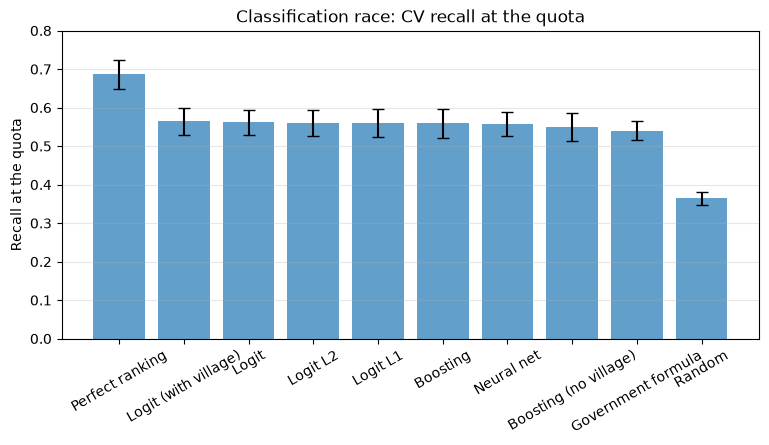

In [21]:
# Plot: recall at the quota, mean and spread across the 5 folds
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(final.index, final["recall mean"], yerr=final["recall std"], capsize=4, alpha=0.7)
ax.set_ylim(0, 0.8)
ax.set_ylabel("Recall at the quota")
ax.set_title("Classification race: CV recall at the quota")
ax.grid(axis="y", alpha=0.3)
ax.tick_params(axis="x", rotation=30)
plt.show()

**Result:**

All classifiers are within one standard deviation of the best one, so the simplicity rule decides: the **logistic regression without penalty wins the classification race**.

The paired check confirms the tie. Fold by fold, boosting minus logit is -0.2 points on average and the neural net minus logit -0.3 points; both are smaller than their spread across the folds.

The logistic regression beats the government formula in 4 of the 5 folds, by 2.1 points on average (std 1.9). Between random (36.4%) and perfect (68.6%) it reaches 61% of the possible improvement, the government formula 55%.

The tuned models (L1, L2, boosting, neural net) have a small advantage, because their settings were chosen on the same folds. The logistic regression without penalty has nothing to tune, so it does not get this bonus, and it still ties.

### 9. Conclusion

In this notebook we predicted poverty directly with five models: logistic regression without penalty, with L2 and with L1, a boosting classifier and a neural network. All used the same village folds, and all filling and scaling happened inside the pipeline. The test villages were not used.

With the log loss, boosting and the neural net look better (0.471) than the logistic regression (0.496). But most of this gap comes from the village-level columns: a logistic regression with these columns reaches 0.479. On the same columns, the flexible models are ahead by less than 0.01. And with recall at the quota, all models find about 56 out of 100 poor households, because the village-level columns help to compare villages but not neighbours.

With the simplicity rule, the logistic regression without penalty wins the classification race. It finds about 2 more poor households out of 100 than the government formula (better in 4 of 5 folds), the same gain as OLS in 04a.

Whether predicting poverty directly is better than predicting consumption is compared in 05_evaluation, together with the final test.